<a href="https://colab.research.google.com/github/Geethika1205/A-4/blob/master/explainable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn lime shap

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [3]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/news_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        print(os.path.join(root, filename))

Dataset extracted successfully!
/content/news_dataset/News _dataset/True.csv
/content/news_dataset/News _dataset/Fake.csv


In [4]:
import pandas as pd

fake_path = "/content/news_dataset/News _dataset/Fake.csv"
true_path = "/content/news_dataset/News _dataset/True.csv"

fake = pd.read_csv(fake_path)
true = pd.read_csv(true_path)

print("Fake news shape:", fake.shape)
print("True news shape:", true.shape)

display(fake.head())
display(true.head())

Fake news shape: (23481, 4)
True news shape: (21417, 4)


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [5]:
fake['label'] = 0
true['label'] = 1

df = pd.concat([fake, true], ignore_index=True)

print("Combined dataset:", df.shape)
print(df['label'].value_counts())

Combined dataset: (44898, 5)
label
0    23481
1    21417
Name: count, dtype: int64


In [6]:
import re

df = df.dropna(subset=['title', 'text'])

df['content'] = df['title'].astype(str) + " " + df['text'].astype(str)

df = df.drop_duplicates(subset=['content'])

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['content'] = df['content'].apply(clean_text)

print("Cleaned dataset:", df.shape)
display(df[['content', 'label']].head())

Cleaned dataset: (39105, 6)


,content,label
0,donald trump sends out embarrassing new year s...,0
1,drunk bragging trump staffer started russian c...,0
2,sheriff david clarke becomes an internet joke ...,0
3,trump is so obsessed he even has obama s name ...,0
4,pope francis just called out donald trump duri...,0


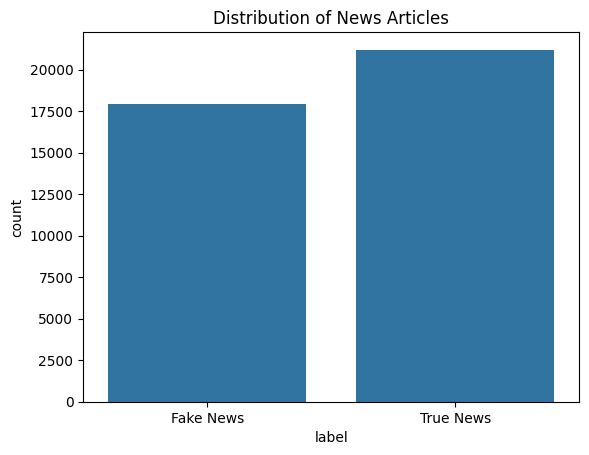

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='label')
plt.xticks([0, 1], ['Fake News', 'True News'])
plt.title("Distribution of News Articles")
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

X = df['content']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 31284
Testing samples: 7821


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words='english',
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

Training features: (31284, 10000)
Testing features: (7821, 10000)


In [10]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


Accuracy: 0.9892596854622171

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      3582
   True News       0.99      0.99      0.99      4239

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821



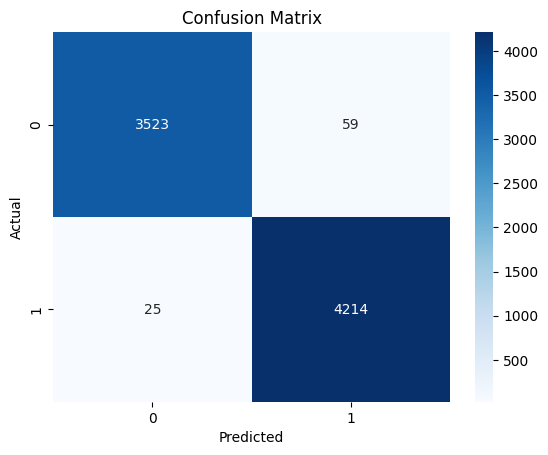

In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Fake News', 'True News']
))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [12]:
from lime.lime_text import LimeTextExplainer

explainer = LimeTextExplainer(
    class_names=['Fake News', 'True News']
)

def predict_probability(texts):
    transformed = tfidf.transform(texts)
    return model.predict_proba(transformed)

sample_text = X_test.iloc[0]

explanation = explainer.explain_instance(
    sample_text,
    predict_probability,
    num_features=10,
    num_samples=1000
)

explanation.show_in_notebook(text=True)

In [14]:

import random
import numpy as np

# Generate slightly modified versions of the article
def perturb_text(text, fraction=0.05):
    words = text.split()
    n_remove = max(1, int(len(words) * fraction))

    if len(words) <= n_remove + 5:
        return text

    indices = set(random.sample(range(len(words)), n_remove))

    return " ".join(
        word for i, word in enumerate(words)
        if i not in indices
    )


# Extract important features from LIME
def get_important_features(text):

    exp = explainer.explain_instance(
        text,
        predict_probability,
        labels=(0, 1),       # Generate both class explanations
        num_features=10,
        num_samples=1000
    )

    return set(
        feature for feature, weight in exp.as_list(label=0)
    )


# Original explanation
original_features = get_important_features(sample_text)

print("Original important features:")
print(original_features)


# Compare modified explanations
similarities = []

random.seed(42)

for i in range(5):

    modified_text = perturb_text(sample_text)

    modified_features = get_important_features(modified_text)

    intersection = original_features & modified_features
    union = original_features | modified_features

    similarity = (
        len(intersection) / len(union) if union else 0
    )

    similarities.append(similarity)

    print(f"Experiment {i+1}: {similarity:.4f}")


# Calculate average stability
stability_score = np.mean(similarities)

print("\nFinal Explanation Stability Score:",
      round(stability_score, 4))


Original important features:
{np.str_('obama'), np.str_('american'), np.str_('hour'), np.str_('ll'), np.str_('america'), np.str_('week'), np.str_('host'), np.str_('sunday'), np.str_('isis'), np.str_('wire')}
Experiment 1: 0.8182
Experiment 2: 0.8182
Experiment 3: 0.6667
Experiment 4: 0.6667
Experiment 5: 0.6667

Final Explanation Stability Score: 0.7273


In [15]:

# Generate LIME explanation for the original article

fidelity_exp = explainer.explain_instance(
    sample_text,
    predict_probability,
    labels=(0, 1),
    num_features=10,
    num_samples=2000
)

# LIME local fidelity score (R-squared)
fidelity_score = fidelity_exp.score

print("Explanation Fidelity Score:",
      round(fidelity_score, 4))

# Interpret the result
if fidelity_score >= 0.8:
    print("Good local approximation")
elif fidelity_score >= 0.5:
    print("Moderate local approximation")
else:
    print("Weak local approximation")


Explanation Fidelity Score: 0.7116
Moderate local approximation


In [16]:

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    accuracy_score
)

# Create calibrated model
calibrated_model = CalibratedClassifierCV(
    estimator=model,
    method='sigmoid',
    cv=5
)

# Train calibration using training data
calibrated_model.fit(X_train_tfidf, y_train)

# Predict probabilities
calibrated_probs = calibrated_model.predict_proba(
    X_test_tfidf
)

calibrated_preds = calibrated_model.predict(
    X_test_tfidf
)

# Evaluate calibration
brier = brier_score_loss(
    y_test,
    calibrated_probs[:, 1]
)

loss = log_loss(
    y_test,
    calibrated_probs
)

accuracy = accuracy_score(
    y_test,
    calibrated_preds
)

print("Calibration Results")
print("-------------------")
print("Accuracy:", round(accuracy, 4))
print("Brier Score:", round(brier, 4))
print("Log Loss:", round(loss, 4))


Calibration Results
-------------------
Accuracy: 0.9893
Brier Score: 0.0086
Log Loss: 0.033


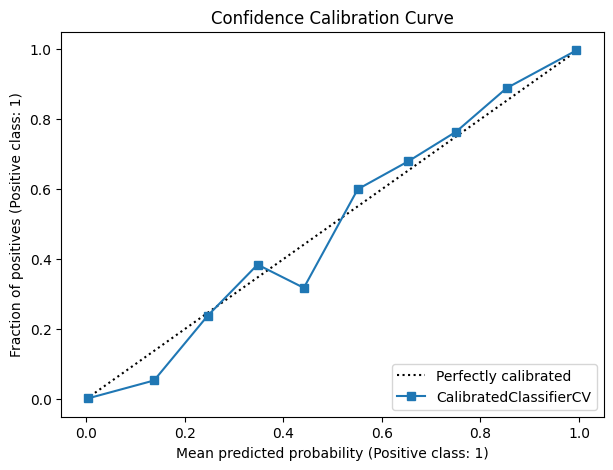

In [17]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(7, 5))

CalibrationDisplay.from_estimator(
    calibrated_model,
    X_test_tfidf,
    y_test,
    n_bins=10,
    strategy='uniform',
    ax=ax
)

plt.title("Confidence Calibration Curve")
plt.show()

In [18]:

import numpy as np
from sklearn.metrics import brier_score_loss, log_loss

def calculate_ece(y_true, probabilities, n_bins=10):

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0

    for i in range(n_bins):

        mask = (
            (probabilities > bin_edges[i]) &
            (probabilities <= bin_edges[i + 1])
        )

        if np.sum(mask) > 0:

            avg_confidence = np.mean(probabilities[mask])
            actual_frequency = np.mean(y_true[mask])

            ece += (
                np.sum(mask) / len(y_true)
            ) * abs(avg_confidence - actual_frequency)

    return ece


# Original model probabilities
original_probs = model.predict_proba(X_test_tfidf)[:, 1]

# Calibrated probabilities
calibrated_probs_positive = calibrated_probs[:, 1]

# Calculate ECE
original_ece = calculate_ece(
    y_test.values, original_probs
)

calibrated_ece = calculate_ece(
    y_test.values, calibrated_probs_positive
)

print("Original ECE:", round(original_ece, 4))
print("Calibrated ECE:", round(calibrated_ece, 4))

print("\nOriginal Brier Score:",
      round(brier_score_loss(y_test, original_probs), 4))

print("Calibrated Brier Score:",
      round(brier_score_loss(y_test, calibrated_probs_positive), 4))


Original ECE: 0.0491
Calibrated ECE: 0.0036

Original Brier Score: 0.0134
Calibrated Brier Score: 0.0086


In [19]:

# Existing experimental measurements

stability_score = 0.7273
fidelity_score = 0.7116

# Use calibrated ECE
calibration_quality = 1 - calibrated_ece

# Proposed weighted Reliability Calibration Score
RCS = (
    0.4 * stability_score +
    0.4 * fidelity_score +
    0.2 * calibration_quality
)

print("RELIABILITY CALIBRATION ANALYSIS")
print("--------------------------------")

print("Stability Score:", round(stability_score, 4))
print("Fidelity Score:", round(fidelity_score, 4))
print("Calibration Quality:", round(calibration_quality, 4))

print("\nFinal Reliability Calibration Score:",
      round(RCS, 4))

print("RCS Percentage:", round(RCS * 100, 2), "%")


RELIABILITY CALIBRATION ANALYSIS
--------------------------------
Stability Score: 0.7273
Fidelity Score: 0.7116
Calibration Quality: 0.9964

Final Reliability Calibration Score: 0.7748
RCS Percentage: 77.48 %


In [20]:

import random
import numpy as np

random.seed(42)

def evaluate_explanation(text, n_perturbations=3):

    # Determine the predicted class
    transformed = tfidf.transform([text])
    predicted_class = int(model.predict(transformed)[0])

    # Original LIME explanation
    exp = explainer.explain_instance(
        text,
        predict_probability,
        labels=(0, 1),
        num_features=10,
        num_samples=1000
    )

    original_features = set(
        feature for feature, weight
        in exp.as_list(label=predicted_class)
    )

    fidelity = exp.score

    # Stability under small perturbations
    similarities = []

    for _ in range(n_perturbations):

        modified_text = perturb_text(text)

        modified_exp = explainer.explain_instance(
            modified_text,
            predict_probability,
            labels=(0, 1),
            num_features=10,
            num_samples=1000
        )

        modified_features = set(
            feature for feature, weight
            in modified_exp.as_list(label=predicted_class)
        )

        intersection = original_features & modified_features
        union = original_features | modified_features

        score = len(intersection) / len(union) if union else 0

        similarities.append(score)

    stability = np.mean(similarities)

    return stability, fidelity


# Evaluate 20 test articles
results = []

for i in range(20):

    text = X_test.iloc[i]

    stability, fidelity = evaluate_explanation(text)

    rcs = (
        0.4 * stability +
        0.4 * fidelity +
        0.2 * (1 - calibrated_ece)
    )

    results.append({
        'Article': i + 1,
        'Stability': stability,
        'Fidelity': fidelity,
        'RCS': rcs
    })

    print(
        f"Article {i+1}: "
        f"Stability={stability:.4f}, "
        f"Fidelity={fidelity:.4f}, "
        f"RCS={rcs:.4f}"
    )

results_df = pd.DataFrame(results)

print("\nDataset Sample Results")
display(results_df)

print("\nAverage Stability:",
      round(results_df['Stability'].mean(), 4))

print("Average Fidelity:",
      round(results_df['Fidelity'].mean(), 4))

print("Average RCS:",
      round(results_df['RCS'].mean(), 4))


Article 1: Stability=0.6667, Fidelity=0.6902, RCS=0.7420
Article 2: Stability=0.4652, Fidelity=0.7093, RCS=0.6691
Article 3: Stability=0.6744, Fidelity=0.8063, RCS=0.7916
Article 4: Stability=0.6667, Fidelity=0.6763, RCS=0.7365
Article 5: Stability=0.2778, Fidelity=0.5617, RCS=0.5351
Article 6: Stability=0.6239, Fidelity=0.7580, RCS=0.7521
Article 7: Stability=0.4701, Fidelity=0.2367, RCS=0.4820
Article 8: Stability=0.4286, Fidelity=0.6929, RCS=0.6479
Article 9: Stability=0.2255, Fidelity=0.6171, RCS=0.5363
Article 10: Stability=0.9394, Fidelity=0.7928, RCS=0.8922
Article 11: Stability=0.9394, Fidelity=0.6913, RCS=0.8516
Article 12: Stability=0.6667, Fidelity=0.6068, RCS=0.7087
Article 13: Stability=0.6239, Fidelity=0.3761, RCS=0.5993
Article 14: Stability=0.5018, Fidelity=0.3901, RCS=0.5560
Article 15: Stability=0.8788, Fidelity=0.9245, RCS=0.9206
Article 16: Stability=0.8788, Fidelity=0.8231, RCS=0.8800
Article 17: Stability=0.6667, Fidelity=0.8866, RCS=0.8206
Article 18: Stability=0

,Article,Stability,Fidelity,RCS
0,1,0.666667,0.690230,0.742044
1,2,0.465201,0.709254,0.669067
2,3,0.674437,0.806251,0.791560
3,4,0.666667,0.676303,0.736473
4,5,0.277778,0.561722,0.535085
5,6,0.623932,0.757990,0.752054
6,7,0.470085,0.236692,0.481996
7,8,0.428571,0.692906,0.647876
8,9,0.225490,0.617069,0.536309
9,10,0.939394,0.792784,0.892156



Average Stability: 0.6326
Average Fidelity: 0.6794
Average RCS: 0.7241


In [21]:

# Provisional threshold for demonstration
RCS_THRESHOLD = 0.70

def detect_unreliable_explanation(row):

    if row['RCS'] < RCS_THRESHOLD:
        return "Potentially Unreliable - Review"

    return "Higher Reliability"


# Apply detection to all 20 articles
results_df['Explanation_Status'] = results_df.apply(
    detect_unreliable_explanation,
    axis=1
)

print("EXPLANATION RELIABILITY DETECTION")
print("----------------------------------")

display(results_df)

# Count the results
print("\nDetection Summary:")

print(
    results_df['Explanation_Status'].value_counts()
)


EXPLANATION RELIABILITY DETECTION
----------------------------------


,Article,Stability,Fidelity,RCS,Explanation_Status
0,1,0.666667,0.690230,0.742044,Higher Reliability
1,2,0.465201,0.709254,0.669067,Potentially Unreliable - Review
2,3,0.674437,0.806251,0.791560,Higher Reliability
3,4,0.666667,0.676303,0.736473,Higher Reliability
4,5,0.277778,0.561722,0.535085,Potentially Unreliable - Review
5,6,0.623932,0.757990,0.752054,Higher Reliability
6,7,0.470085,0.236692,0.481996,Potentially Unreliable - Review
7,8,0.428571,0.692906,0.647876,Potentially Unreliable - Review
8,9,0.225490,0.617069,0.536309,Potentially Unreliable - Review
9,10,0.939394,0.792784,0.892156,Higher Reliability



Detection Summary:
Explanation_Status
Higher Reliability                 13
Potentially Unreliable - Review     7
Name: count, dtype: int64


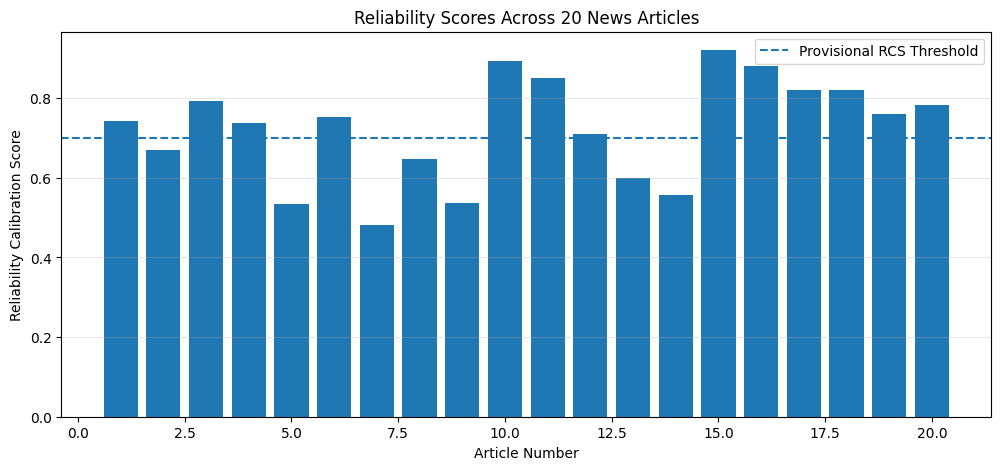

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.bar(
    results_df['Article'],
    results_df['RCS']
)

plt.axhline(
    y=RCS_THRESHOLD,
    linestyle='--',
    label='Provisional RCS Threshold'
)

plt.xlabel("Article Number")
plt.ylabel("Reliability Calibration Score")
plt.title("Reliability Scores Across 20 News Articles")

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

In [23]:

# Count potentially unreliable explanations

unreliable = results_df[
    results_df['RCS'] < RCS_THRESHOLD
]

reliable = results_df[
    results_df['RCS'] >= RCS_THRESHOLD
]

print("FINAL DETECTION SUMMARY")
print("-----------------------")

print("Total Articles:", len(results_df))

print("Higher Reliability:",
      len(reliable))

print("Flagged for Review:",
      len(unreliable))

print("Average RCS:",
      round(results_df['RCS'].mean(), 4))

print("\nArticles Flagged for Review:")

display(
    unreliable[
        ['Article', 'Stability', 'Fidelity', 'RCS']
    ]
)


FINAL DETECTION SUMMARY
-----------------------
Total Articles: 20
Higher Reliability: 13
Flagged for Review: 7
Average RCS: 0.7241

Articles Flagged for Review:


,Article,Stability,Fidelity,RCS
1,2,0.465201,0.709254,0.669067
4,5,0.277778,0.561722,0.535085
6,7,0.470085,0.236692,0.481996
7,8,0.428571,0.692906,0.647876
8,9,0.225490,0.617069,0.536309
12,13,0.623932,0.376113,0.599303
13,14,0.501832,0.390067,0.556044


In [24]:
results_df.to_csv(
    "reliability_calibration_results.csv",
    index=False
)

from google.colab import files

files.download("reliability_calibration_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

import shap
import numpy as np
import matplotlib.pyplot as plt

# Select a small background dataset
background = X_train_tfidf[:100]

# Create SHAP explainer for Logistic Regression
shap_explainer = shap.LinearExplainer(
    model,
    background
)

# Select one test article
sample_vector = X_test_tfidf[0]

# Generate SHAP explanation
shap_values = shap_explainer(
    sample_vector
)

print("SHAP explanation generated successfully!")

print("Number of features:",
      len(tfidf.get_feature_names_out()))


SHAP explanation generated successfully!
Number of features: 10000


In [26]:
feature_names = np.array(tfidf.get_feature_names_out())

values = shap_values.values[0]

top_indices = np.argsort(np.abs(values))[-15:][::-1]

for idx in top_indices:
    print(
        feature_names[idx],
        round(values[idx], 5)
    )

wire -1.79963
said -0.69912
sunday 0.36707
reuters -0.30485
america -0.21882
week 0.18782
episode -0.18532
ll -0.17731
live -0.15099
american -0.14643
obama -0.14566
isis -0.14315
host -0.14147
video 0.1023
pm -0.09159


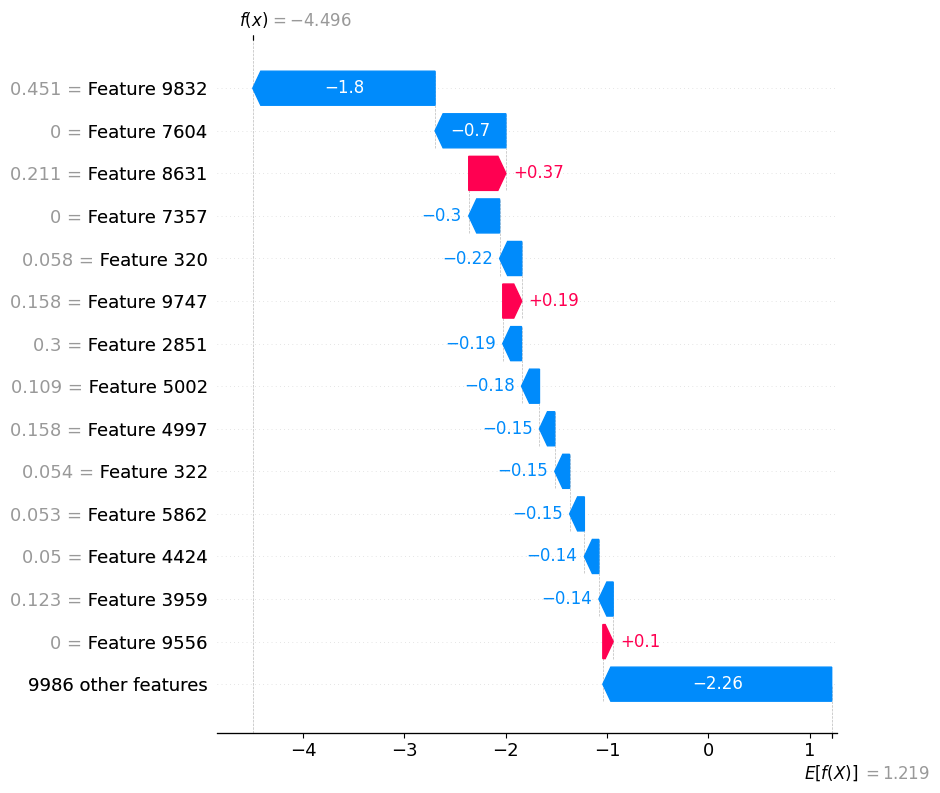

In [27]:
shap.plots.waterfall(
    shap_values[0],
    max_display=15
)

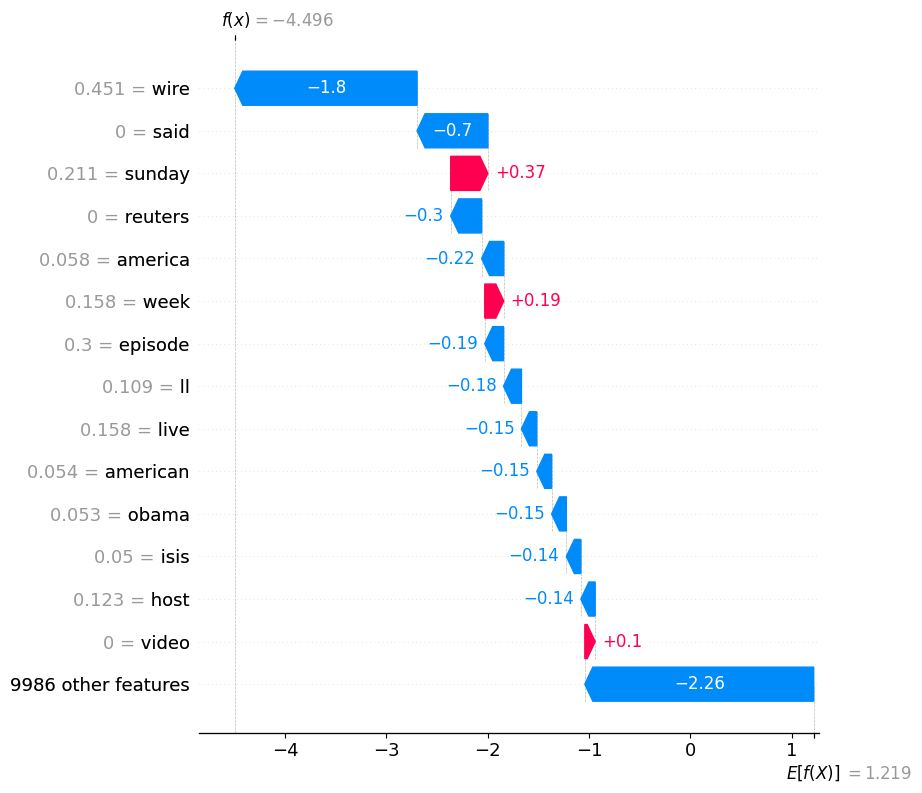

In [28]:

import shap
import numpy as np

# Get actual vocabulary words
feature_names = tfidf.get_feature_names_out()

# Convert the selected article into a dense array
sample_data = sample_vector.toarray()[0]

# Create a readable SHAP explanation
readable_shap = shap.Explanation(
    values=shap_values.values[0],
    base_values=float(np.asarray(shap_values.base_values).reshape(-1)[0]),
    data=sample_data,
    feature_names=feature_names
)

# Display actual words
shap.plots.waterfall(
    readable_shap,
    max_display=15
)


In [29]:

# Generate LIME explanation for the same article

lime_exp = explainer.explain_instance(
    sample_text,
    predict_probability,
    labels=(0, 1),
    num_features=15,
    num_samples=1000
)

# Extract LIME important words for Fake News
lime_features = set(
    word for word, weight in lime_exp.as_list(label=0)
)

# Extract SHAP important features
shap_importance = np.abs(shap_values.values[0])

top_shap_indices = np.argsort(
    shap_importance
)[-15:][::-1]

shap_features = set(
    feature_names[i] for i in top_shap_indices
)

# Compare the two methods
common_features = lime_features.intersection(
    shap_features
)

all_features = lime_features.union(
    shap_features
)

overlap_score = (
    len(common_features) / len(all_features)
    if all_features else 0
)

print("LIME vs SHAP COMPARISON")
print("-----------------------")

print("\nLIME Features:")
print(lime_features)

print("\nSHAP Features:")
print(shap_features)

print("\nCommon Features:")
print(common_features)

print("\nFeature Overlap Score:",
      round(overlap_score, 4))


LIME vs SHAP COMPARISON
-----------------------

LIME Features:
{np.str_('new'), np.str_('broadcast'), np.str_('war'), np.str_('news'), np.str_('obama'), np.str_('hour'), np.str_('america'), np.str_('ll'), np.str_('week'), np.str_('ukraine'), np.str_('host'), np.str_('sunday'), np.str_('isis'), np.str_('wire'), np.str_('annual')}

SHAP Features:
{'pm', 'live', 'american', 'obama', 'said', 'america', 'reuters', 'week', 'episode', 'll', 'video', 'host', 'sunday', 'isis', 'wire'}

Common Features:
{'sunday', 'america', 'll', 'week', 'host', 'obama', 'isis', 'wire'}

Feature Overlap Score: 0.3636


In [30]:

import numpy as np
import pandas as pd

comparison_results = []

feature_names = tfidf.get_feature_names_out()

for i in range(20):

    text = X_test.iloc[i]

    # LIME explanation
    lime_exp = explainer.explain_instance(
        text,
        predict_probability,
        labels=(0, 1),
        num_features=15,
        num_samples=1000
    )

    predicted_class = int(
        model.predict(tfidf.transform([text]))[0]
    )

    lime_words = set(
        word for word, weight
        in lime_exp.as_list(label=predicted_class)
    )

    # SHAP explanation
    vector = tfidf.transform([text])

    shap_exp = shap_explainer(
        vector
    )

    shap_scores = np.abs(shap_exp.values[0])

    top_indices = np.argsort(shap_scores)[-15:]

    shap_words = set(
        feature_names[j] for j in top_indices
    )

    # Jaccard overlap
    intersection = lime_words & shap_words
    union = lime_words | shap_words

    overlap = (
        len(intersection) / len(union)
        if union else 0
    )

    comparison_results.append({
        'Article': i + 1,
        'Common Features': len(intersection),
        'Feature Overlap': overlap
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

print(
    "Average LIME-SHAP Overlap:",
    round(comparison_df['Feature Overlap'].mean(), 4)
)


,Article,Common Features,Feature Overlap
0,1,10,0.500000
1,2,7,0.304348
2,3,9,0.428571
3,4,8,0.363636
4,5,7,0.304348
5,6,9,0.428571
6,7,9,0.428571
7,8,8,0.363636
8,9,6,0.250000
9,10,8,0.363636


Average LIME-SHAP Overlap: 0.4332
